<table style="border:none;border-collapse:collapse;margin:0 0 8px;width:100%;">
<tr style="border:none;">
  <td style="border:none;padding:0;vertical-align:middle;">
    <div style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.2em;text-transform:uppercase;color:#A20025;margin:0 0 7px;">Companion notebook</div>
    <div style="font-family:Georgia,'Iowan Old Style',serif;font-size:18px;color:#1A1416;line-height:1.25;margin:0 0 7px;">
      <a href="https://www.manning.com/books/build-ai-drug-discovery-pipelines" style="color:#1A1416;text-decoration:none;border-bottom:1px solid #A20025;padding-bottom:1px;">Build AI Drug Discovery Pipelines</a>
    </div>
    <div style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:12px;color:#6B6461;line-height:1.7;">
      Noah Flynn&nbsp;&middot;&nbsp;Manning Publications<br>
      Code&nbsp;&middot;&nbsp;<a href="https://github.com/nrflynn2/ml-drug-discovery" style="color:#A20025;text-decoration:none;">github.com/nrflynn2/ml-drug-discovery</a>
    </div>
  </td>
  <td style="border:none;padding:0 0 0 22px;vertical-align:middle;width:104px;text-align:right;">
    <a href="https://www.manning.com/books/build-ai-drug-discovery-pipelines">
      <img src="https://raw.githubusercontent.com/nrflynn2/ml-drug-discovery/main/assets/cover-sm.png" width="88" alt="Build AI Drug Discovery Pipelines cover" style="border:1px solid #E7E2DF;border-radius:3px;display:inline-block;">
    </a>
  </td>
</tr>
</table>
<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:0 0 22px;">

<div style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:11px;letter-spacing:.24em;text-transform:uppercase;color:#A20025;margin:0 0 12px;">Chapter 13 &middot; Notebook 1</div>

<h1 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:33px;line-height:1.12;margin:0 0 16px;color:#1A1416;letter-spacing:-.01em;">Calling the BioNeMo NIMs: What Pose Confidence and Predicted Affinity Actually Tell You</h1>

<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:0 0 4px;">

<em style="color:#6B6461;font-size:14.5px;">Runnable code for Chapter 13; read alongside the book.</em>

<a href="https://colab.research.google.com/github/nrflynn2/ml-drug-discovery/blob/main/CH13_NB1_FLYNN_ML4DD.ipynb" target="_blank"><img src="https://img.shields.io/badge/Open%20in-Colab-A20025?logo=googlecolab&logoColor=white" alt="Open in Colab" style="height:20px;vertical-align:middle;"></a>

<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:11px;letter-spacing:.16em;text-transform:uppercase;color:#A20025;">Objectives</strong>
<ol style="margin:8px 0 0;padding-left:22px;font-size:15.5px;color:#241c1d;">
<li style="margin:6px 0;">Call the hosted Boltz-2 and DiffDock NIMs from Python and read their raw JSON response fields</li>
<li style="margin:6px 0;">Convert a Boltz-2 <code>affinity_pred_value</code> into a pIC50 correctly, and recognise why the endpoint's own <code>affinity_pic50</code> field must not be used</li>
<li style="margin:6px 0;">Apply the binder-probability gate in the right order and tell a confident call from an uncalibrated one</li>
<li style="margin:6px 0;">Rank a real 18-ligand TNIK series by predicted affinity and by pose confidence, and measure which one tracks measured potency</li>
<li style="margin:6px 0;">State the limits of what you measured: per-target bias, range compression, and pose recovery versus prospective prediction</li>
</ol>

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§0&#8195;</span>Environment Setup</h2>

<div style="font-size:14px;margin:0 0 6px;">
<div style="display:flex;gap:14px;padding:9px 0;border-bottom:1px solid #EFEBE8;"><strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:11px;letter-spacing:.06em;text-transform:uppercase;color:#A20025;min-width:96px;">Local&#8195;&#8195;</strong><span>Install <a href="https://docs.astral.sh/uv/" style="color:#A20025;">uv</a>, then run <code>uv sync --extra advanced</code> from the repo root (Python 3.12) and launch with <code>uv run jupyter lab</code>. This notebook needs only pandas, numpy, scipy, matplotlib and rdkit from that tier, plus the standard library.</span></div>
<div style="display:flex;gap:14px;padding:9px 0;"><strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:11px;letter-spacing:.06em;text-transform:uppercase;color:#A20025;min-width:96px;">Colab&#8195;&#8195;</strong><span>Run the install cell below, then restart the runtime. The whole notebook runs on CPU; there is no GPU requirement, because the two models run on NVIDIA's servers rather than yours.</span></div>
</div>

<div style="margin:0 0 16px;padding:2px 0 2px 18px;border-left:2px solid #A20025;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#A20025;">Note</strong>
<div style="color:#3d3436;font-size:14.5px;">
<p><strong>Two ways to run this notebook.</strong> Every result below was produced by calling the live
BioNeMo endpoints, and every one of those results is also saved as a CSV in <code>data/ch13/</code>.
The flag <code>USE_CACHED</code> in the setup cell picks which path you take.</p>
<ul>
<li><strong><code>USE_CACHED = True</code></strong> (the default) reads the saved CSVs. No API key, no
network, no cost. Runs top to bottom in well under a minute and prints exactly the numbers discussed in
the prose.</li>
<li><strong><code>USE_CACHED = False</code></strong> calls the endpoints for real. You need a free NVIDIA
API key. Expect roughly 8 minutes of wall-clock for the 18-ligand set at the per-call latency we measured,
and anywhere from 3 to 15 minutes depending on how busy the queue is. Only about 100 seconds of that is
actual GPU compute; the rest is queue.</li>
</ul>
<p>The live path will not reproduce the cached numbers to the last decimal, and section 5 explains why
that is a property of the model rather than a bug in the notebook.</p>
</div>
</div>

In [1]:
# Colab only: install the packages this notebook uses, then restart the runtime.
# Everything here is CPU-only; the two models run on NVIDIA's servers, not yours.
# !pip install -q "pandas>=2.2.3,<3.0" "numpy>=1.26.4,<2.3" "scipy>=1.15.0" \
#     "matplotlib>=3.10.0" "rdkit>=2024.3.2"

from pathlib import Path
import urllib.request

def fetch(url: str, dest, force: bool = False) -> Path:
    """Download `url` to `dest` if not already present. Cross-platform, no shell."""
    dest = Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    if force or not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

# The cached endpoint results and the receptor structure. On Colab these are pulled from
# the repo; locally they are already in data/ch13/ and fetch() is a no-op.
RAW = "https://raw.githubusercontent.com/nrflynn2/ml-drug-discovery/main/data/ch13/"
DATA = Path("data/ch13")
for _f in [
    "tnik_ligands.csv",                       # the 18-ligand TNIK series with measured IC50s
    "boltz2_affinity_tnik_tyk2_gated.csv",    # cached Boltz-2 affinity calls (TNIK + TYK2)
    "tnik_diffdock_confidence.csv",           # cached DiffDock confidence for the same 18
    "rentosertib_rank_vs_rmsd.csv",           # pose-recovery RMSDs, 4 runs x 20 poses
    "boltz2_affinity_timing.csv",             # per-call wall and server timings
    "rentosertib_potency_provenance.csv",     # every literature potency value, with its assay
    "TNIK_8ZML_receptor_chainA.pdb",          # receptor: 8ZML chain A, ATOM records only
    "rentosertib_rank1_pose.sdf",             # rank-1 docked pose
    "8ZML_rentosertib_refpose.sdf",           # crystallographic reference pose
]:
    fetch(RAW + _f, DATA / _f)

print(f"{len(list(DATA.iterdir()))} files ready in {DATA}")

9 files ready in data/ch13


<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Import Packages</h3>

In [2]:
import json
import os
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# ---- The two switches that govern this notebook -------------------------------
USE_CACHED = True     # True: read data/ch13/*.csv. False: call the live endpoints.
SEED = 2              # fixes the bootstrap resampling for the confidence intervals

# Monograph plotting defaults (TEMPLATE.md palette).
mpl.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 150, "figure.figsize": (7, 4.3),
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E7E2DF", "grid.linewidth": 0.6,
    "axes.edgecolor": "#6B6461", "text.color": "#1A1416", "axes.labelcolor": "#3d3436",
})
CRIMSON, INK, MUTED, AMBER, HAIRLINE = "#A20025", "#1A1416", "#6B6461", "#B4690E", "#E7E2DF"

Path("figures/ch13").mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(SEED)
pd.set_option("display.width", 200)

print(f"mode: {'CACHED (no API calls)' if USE_CACHED else 'LIVE (calls NVIDIA endpoints)'}")
print(f"seed: {SEED}")

mode: CACHED (no API calls)
seed: 2


<h4 style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-weight:600;font-size:11.5px;letter-spacing:.1em;text-transform:uppercase;color:#A20025;margin:18px 0 6px;">Credentials</h4>

The live path needs an NVIDIA API key. Getting one is free: sign in at
[build.nvidia.com](https://build.nvidia.com/), open either the
[Boltz-2](https://build.nvidia.com/mit/boltz2) or the [DiffDock](https://build.nvidia.com/mit/diffdock)
model page, and click "Get API Key". The key arrives as a string beginning `nvapi-`, and a new account
comes with enough free credits to run everything in this notebook several times over.

We read that key from an environment variable rather than typing it into a cell. This is not
bureaucratic caution. A key pasted into a notebook gets committed to git, pushed to GitHub, and scraped
within hours; a key in the environment stays out of the file you share. Set it in your shell before
launching Jupyter:

```bash
export NVIDIA_API_KEY="nvapi-..."     # macOS / Linux
setx NVIDIA_API_KEY "nvapi-..."       # Windows, then reopen the terminal
```

On Colab, use the key icon in the left sidebar to add a secret named `NVIDIA_API_KEY`, enable notebook
access, and the cell below will pick it up.

In [3]:
def get_api_key() -> str:
    """Return the NVIDIA API key from the environment, or explain how to set one.

    Reads Colab's secret store first (where a key added via the sidebar lives), then
    falls back to a plain environment variable. Only the key's presence and length are
    ever reported, so no part of its value can reach a notebook output or a git diff.
    """
    key = os.environ.get("NVIDIA_API_KEY", "")
    if not key:
        try:                                    # Colab secrets, if we are on Colab
            from google.colab import userdata
            key = userdata.get("NVIDIA_API_KEY") or ""
        except Exception:
            pass
    if not key:
        raise RuntimeError(
            "No NVIDIA_API_KEY found, so the live path cannot run.\n"
            "\n"
            "You have two options:\n"
            "  1. Set USE_CACHED = True in the imports cell above and re-run. Every result\n"
            "     in this notebook is cached in data/ch13/, so you lose nothing but the\n"
            "     experience of watching the calls go out.\n"
            "  2. Get a free key at https://build.nvidia.com/mit/boltz2 (click 'Get API\n"
            "     Key'), then set it in your shell:\n"
            "         export NVIDIA_API_KEY='nvapi-...'\n"
            "     and restart the kernel. On Colab, add it as a secret named\n"
            "     NVIDIA_API_KEY using the key icon in the left sidebar.\n"
        )
    return key


BOLTZ2_URL = "https://health.api.nvidia.com/v1/biology/mit/boltz2/predict"
DIFFDOCK_URL = "https://health.api.nvidia.com/v1/biology/mit/diffdock"

if USE_CACHED:
    print("cached mode: no key needed")
else:
    _k = get_api_key()
    print(f"key found ({len(_k)} characters); its value is never printed or logged")
    del _k

cached mode: no key needed


<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§1&#8195;</span>The Claim Worth Testing</h2>

Chapter 13 makes a promise on your behalf. It tells you that each BioNeMo NIM
"provides a REST API for model inference", and then it moves on to architecture diagrams without ever
showing you one of those calls. This notebook is that missing call. We will hit two hosted endpoints,
read what actually comes back, and then do the thing the chapter cannot do in prose: check whether the
numbers in the response mean what the field names suggest they mean.

That check matters more than it sounds. Two of the components the chapter describes have a division of
labour that is easy to state and easy to forget. DiffDock predicts where a ligand sits in a binding site
and how confident it is about that geometry; it does not predict how tightly the ligand binds. Boltz-2
predicts the affinity. If you conflate the two you will rank a compound library by a number that has no
relationship to potency, and you will do it while looking at a plausible-seeming confidence score. By the
end of section 4 you will have measured exactly how badly that goes wrong.

Here is the route. First we assemble a real test set: 18 TNIK inhibitors from a single published
radiometric assay, so the potencies are comparable to each other, plus the co-crystal structure of the
most interesting one. Then we call Boltz-2 on one ligand and read the raw response, where we meet the
single most expensive mistake this endpoint invites. Then we teach the binder-probability gate, score the
whole series, dock the same 18 with DiffDock, and correlate both predictions against measured potency.
Finally we look hard at what the correlation does not tell us.

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">The target and the series</h3>

TNIK (TRAF2- and NCK-interacting kinase) is a serine/threonine kinase in the Wnt
signalling pathway and a target in idiopathic pulmonary fibrosis. It is a good choice for this exercise
for a practical reason: rentosertib, an AI-discovered TNIK inhibitor, reached Phase IIa, and its complex
with TNIK was solved and deposited as PDB entry **8ZML**. That gives us a ligand with a published
potency, a crystal structure to compare a docked pose against, and 17 analogs measured in the same assay
from the same paper.

That last point is what makes the experiment interpretable. A pIC50 (the negative base-10 logarithm of
the IC50 in molar units, so a larger pIC50 means a more potent compound) is only comparable to another
pIC50 when both came from the same assay under the same conditions. Mixing assays smuggles in a variance
you will later mistake for model error. All 18 compounds below were measured in one radiometric assay
reported in one J Med Chem paper, and they span 4.0 nM to 13,835 nM: three and a half orders of
magnitude, wide enough for a ranking question to be meaningful.

In [4]:
ligands = pd.read_csv(DATA / "tnik_ligands.csv")

# pActivity is -log10(IC50 in molar); value_nM is the same measurement in nanomolar.
series = (ligands[["chembl_id", "smiles", "value_nM", "pActivity", "is_rentosertib"]]
          .sort_values("value_nM")
          .reset_index(drop=True))

print(f"{len(series)} ligands, one assay, one paper")
print(f"potency span: {series.value_nM.min():.1f} nM to {series.value_nM.max():,.0f} nM "
      f"({series.pActivity.max() - series.pActivity.min():.2f} log units)")
print(f"unique assay ids in the set: {ligands.assay_chembl_id.nunique()}")
print(f"assay: {ligands.assay_description.iloc[0][:84]}")
print()
print(series.head(6).to_string(index=False))

18 ligands, one assay, one paper
potency span: 4.0 nM to 13,835 nM (3.54 log units)
unique assay ids in the set: 1
assay: Inhibition of human recombinant TNIK (1 to 367 residues) using RLGRDKYKTLRQI as subs

    chembl_id                                                                 smiles  value_nM  pActivity  is_rentosertib
CHEMBL6149740               O=C(Nc1ccccc1F)c1c[nH]c(-c2c(-c3ccc(F)cc3)ncn2C2CCCC2)n1       4.0      8.398           False
CHEMBL6016120          CC(C)n1cnc(-c2ccc(F)cc2)c1-c1cccc(C(=O)Nc2ccc(CCC(=O)O)cc2)n1       5.7      8.244           False
CHEMBL5969552     CC(C)n1cnc(-c2ccc(F)cc2)c1-c1nc(C(=O)Nc2ccc(N3CCN(C)CC3)cc2)c[nH]1       7.8      8.108            True
CHEMBL5826891        CC(C)n1cnc(-c2ccc(F)cc2)c1-c1ccc(C(=O)Nc2ccc(N3CCN(C)CC3)cc2)o1      10.5      7.979           False
CHEMBL6152952                    CC(C)n1cnc(-c2ccc(F)cc2)c1-c1ccc(C(=O)Nc2ccccc2F)o1      11.1      7.955           False
CHEMBL5780397 CC1CN(c2ccc(NC(=O)c3c[nH]c(-c4c(-c5ccc(F)cc5)n

The compound flagged `is_rentosertib` is the clinical molecule, third-most-potent of the 18
at 7.8 nM in this assay. That 7.8 nM deserves a footnote, because it illustrates why a single potency
number is a weaker fact than it looks.

<div style="margin:0 0 16px;padding:2px 0 2px 18px;border-left:2px solid #B4690E;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#B4690E;">Caution</strong><br>
<span style="color:#3d3436;font-size:14.5px;">A bare "IC50 = X nM" for an ATP-competitive kinase inhibitor is under-specified. Rentosertib
measures 14.7 nM in a FRET assay run at 64 micromolar ATP and 257.2 nM in the same FRET assay at 2
millimolar ATP: a 17.5-fold shift from ATP concentration alone, with no change to the compound. The
radiometric value we use here is 7.8 nM, and the primary Nature Biotechnology paper reports 31 nM from a
different panel. None of these numbers is wrong. They answer slightly different questions. When you
compare a predicted affinity against a literature value you are comparing against one assay's answer,
and the spread between assays sets a floor on how well any model can appear to do.</span>
</div>

In [5]:
prov = pd.read_csv(DATA / "rentosertib_potency_provenance.csv")

# Every literature potency for rentosertib we could trace to a primary source, with the
# assay conditions that produced it. Same molecule, same target, every row.
print(prov[["value", "measurement_type", "atp_conc", "source"]]
      .assign(source=lambda d: d.source.str.replace("\u2014", "-", regex=False).str.slice(0, 44))
      .to_string(index=False))

                        value              measurement_type                                                                     atp_conc                                       source
                 IC50 = 31 nM              IC50 (enzymatic) Km ATP (paper states both compared assays use Km ATP; exact value not given) Ren et al., Nat Biotechnol 2025, 43:63-75 (P
                 Kd = 4.32 nM           Kd (direct binding)                                                  n/a (binding assay, no ATP) Ren et al., Nat Biotechnol 2025 (same paper)
                IC50 = 7.8 nM IC50 (enzymatic, radiometric)                                   not stated in the ChEMBL assay description Aladinskiy et al., J Med Chem 2024, 67 (PMID
               IC50 = 14.7 nM  IC50 (FRET, ATP-competitive)                                                                    64 uM ATP Aladinskiy et al., J Med Chem 2024 - FRET, L
              IC50 = 257.2 nM  IC50 (FRET, ATP-competitive)                               

The last row is a different molecule entirely: CHEMBL5780397, a dimethylpiperazine analog
measured in the same assay in the same paper, at 18.0 nM. It is in the table because that value
circulates attached to rentosertib's name, and the only defence against that kind of drift is to keep
the assay and the compound identifier next to the number.

Now the structure. DiffDock takes receptor coordinates as PDB text, and it wants ATOM records only:
headers, waters, and heteroatoms all need to go, including the crystallographic ligand we are about to
try to rediscover. Leaving that ligand in place would be leakage of the most literal kind.

In [6]:
receptor_pdb = (DATA / "TNIK_8ZML_receptor_chainA.pdb").read_text()
atom_lines = [ln for ln in receptor_pdb.splitlines() if ln.startswith("ATOM")]

# Confirm the receptor is clean: nothing but protein backbone and side chains.
record_types = sorted({ln[:6].strip() for ln in receptor_pdb.splitlines() if ln.strip()})
residues = {ln[22:27] for ln in atom_lines}
n_hetatm = sum(1 for ln in receptor_pdb.splitlines() if ln.startswith("HETATM"))

print("receptor: 8ZML chain A")
print(f"  record types present : {record_types}")
print(f"  ATOM lines           : {len(atom_lines):,}")
print(f"  residues             : {len(residues)}")
print(f"  HETATM / waters      : {n_hetatm}")
assert n_hetatm == 0, "crystallographic ligand still present; docking would be leakage"

RECEPTOR = "\n".join(atom_lines)

receptor: 8ZML chain A
  record types present : ['ATOM']
  ATOM lines           : 2,405
  residues             : 299
  HETATM / waters      : 0


Boltz-2 works from sequence rather than coordinates, so we need the same chain as a
one-letter amino-acid string. Extracting it from the PDB rather than fetching it from UniProt keeps the
two models looking at the same construct, which matters: a sequence with 20 extra residues on the
terminus is a different prediction problem.

In [7]:
AA3_TO_1 = {
    "ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E",
    "GLY": "G", "HIS": "H", "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F",
    "PRO": "P", "SER": "S", "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V",
}

def sequence_from_pdb(pdb_text: str, chain: str = "A") -> str:
    """One-letter sequence for `chain`, in residue order, from ATOM records."""
    seen, seq = set(), []
    for ln in pdb_text.splitlines():
        if ln.startswith("ATOM") and ln[21] == chain:
            resnum = ln[22:27]
            if resnum not in seen:
                seen.add(resnum)
                seq.append(AA3_TO_1.get(ln[17:20].strip(), "X"))
    return "".join(seq)


SEQUENCE = sequence_from_pdb(receptor_pdb)
print(f"{len(SEQUENCE)} residues, {SEQUENCE.count('X')} unresolved")
print(f"hinge region: ...{SEQUENCE[100:115]}...   (Met105 gatekeeper, Cys108 hinge)")

299 residues, 0 unresolved
hinge region: ...GSVTDLIKNTKGNTL...   (Met105 gatekeeper, Cys108 hinge)


<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§2&#8195;</span>One Call, and the Number That Lies</h2>

Time to call the thing. The Boltz-2 NIM takes a JSON body describing the polymers and
ligands you want folded together. Affinity prediction is opt-in per ligand and limited to one ligand per
request, and that constraint shapes the whole workflow: scoring a library means one HTTP request per
compound, not one batched request.

The parameters below are the endpoint's own defaults, spelled out rather than omitted so you can see what
you are getting. A `diffusion_samples_affinity` of 5 means the affinity head runs five times and the
results are aggregated, which is worth remembering when we reach reproducibility in section 5.

In [8]:
import urllib.error
import urllib.request


def post_json(url: str, body: dict, api_key: str, timeout: int = 600) -> dict:
    """POST `body` as JSON with bearer auth and return the parsed response.

    Uses urllib so the notebook needs nothing beyond the standard library, and surfaces
    the server's own error text, which is where the useful diagnostics live.
    """
    req = urllib.request.Request(
        url,
        data=json.dumps(body).encode(),
        headers={
            "Authorization": f"Bearer {api_key}",     # the key is never logged
            "Content-Type": "application/json",
            "Accept": "application/json",
        },
        method="POST",
    )
    try:
        with urllib.request.urlopen(req, timeout=timeout) as resp:
            return json.loads(resp.read())
    except urllib.error.HTTPError as err:
        detail = err.read().decode(errors="replace")[:400]
        if err.code == 401:
            raise RuntimeError(
                "401 Unauthorized: the endpoint rejected the API key. Check that "
                "NVIDIA_API_KEY holds the full 'nvapi-...' string and has not expired."
            ) from None
        raise RuntimeError(f"HTTP {err.code} from {url}\n{detail}") from None


def boltz2_affinity(sequence: str, smiles: str, api_key: str) -> dict:
    """Co-fold one protein with one ligand and ask for an affinity prediction.

    Returns the raw response dict. Interpretation is deliberately left to the caller;
    the next few cells are entirely about what these fields mean.
    """
    body = {
        "polymers": [{"id": "A", "molecule_type": "protein", "sequence": sequence}],
        "ligands": [{"id": "LIG", "smiles": smiles, "predict_affinity": True}],
        "recycling_steps": 3,             # endpoint defaults, stated explicitly
        "sampling_steps": 50,
        "diffusion_samples": 1,
        "step_scale": 1.638,
        "sampling_steps_affinity": 200,
        "diffusion_samples_affinity": 5,  # the affinity head runs 5x, then aggregates
        "output_format": "mmcif",
    }
    return post_json(BOLTZ2_URL, body, api_key)

<div style="margin:0 0 16px;padding:2px 0 2px 18px;border-left:2px solid #6B6461;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#6B6461;">Runtime</strong><br>
<span style="color:#3d3436;font-size:14.5px;">A single Boltz-2 affinity call takes about 5.6 seconds of server compute but 10 to 45
seconds of wall-clock, because most of that wall time is queueing on NVIDIA's side. In cached mode the
cell below is instant. In live mode, expect to wait about half a minute for one ligand.</span>
</div>

We call it on rentosertib and look at the response with no interpretation at all. Print the
field names first, then the numbers. The response shape is the API contract, and reading it before
reaching for the value you want is the habit that catches the problem below.

In [9]:
RENTOSERTIB = series.loc[series.is_rentosertib, "smiles"].iloc[0]
cached_calls = pd.read_csv(DATA / "boltz2_affinity_tnik_tyk2_gated.csv")

BOLTZ2_TOP_LEVEL_KEYS = [
    "affinities", "chains_ptm_scores", "complex_ipde_scores", "complex_iplddt_scores",
    "complex_pde_scores", "complex_plddt_scores", "confidence_scores", "iptm_scores",
    "ligand_iptm_scores", "metrics", "pae", "pair_chains_iptm_scores", "pde",
    "protein_iptm_scores", "ptm_scores", "structures",
]

if USE_CACHED:
    # Rebuild the affinity block exactly as the endpoint returned it, from the per-field
    # columns saved when these calls were made. Same field names, same list-of-one shape.
    row = cached_calls.query("is_rentosertib").iloc[0]
    affinity = {
        "affinity_pred_value": [row.affinity_pred_value],
        "affinity_probability_binary": [row.affinity_probability_binary],
        "affinity_pic50": [row.affinity_pic50_RESPONSE_FIELD_DO_NOT_USE],
        "model_1_affinity_pred_value": [row.model_1_affinity_pred_value],
        "model_2_affinity_pred_value": [row.model_2_affinity_pred_value],
        "model_1_affinity_probability_binary": [row.model_1_affinity_probability_binary],
        "model_2_affinity_probability_binary": [row.model_2_affinity_probability_binary],
    }
    server_seconds = float(row.server_total_seconds)
    top_level = BOLTZ2_TOP_LEVEL_KEYS
else:
    t0 = time.perf_counter()
    response = boltz2_affinity(SEQUENCE, RENTOSERTIB, get_api_key())
    wall = time.perf_counter() - t0
    affinity = response["affinities"]["LIG"]
    server_seconds = float(response["metrics"]["total_time_seconds"])
    top_level = sorted(response.keys())
    print(f"live call: {wall:.1f} s wall, {server_seconds:.2f} s server compute\n")

print("top-level response keys:")
print("  " + ", ".join(top_level))
print()
print("affinities['LIG'] fields:")
for field, value in affinity.items():
    print(f"  {field:<40s} {float(value[0]):>12.6f}")

top-level response keys:
  affinities, chains_ptm_scores, complex_ipde_scores, complex_iplddt_scores, complex_pde_scores, complex_plddt_scores, confidence_scores, iptm_scores, ligand_iptm_scores, metrics, pae, pair_chains_iptm_scores, pde, protein_iptm_scores, ptm_scores, structures

affinities['LIG'] fields:
  affinity_pred_value                         -2.484375
  affinity_probability_binary                  0.921875
  affinity_pic50                              11.572688
  model_1_affinity_pred_value                 -2.593750
  model_2_affinity_pred_value                 -2.375000
  model_1_affinity_probability_binary          0.980469
  model_2_affinity_probability_binary          0.863281


Note the shape: every affinity field is a one-element **list**, not a scalar. That is a
small thing that will bite you the first time you write `affinity["affinity_pred_value"] * 2` and get a
two-element list back instead of a doubled number.

Now the substance. There are two numbers in that block a newcomer would reach for, and they disagree with
each other. `affinity_pred_value` is the model's affinity output. `affinity_pic50` is a field whose name
says, in plain language, that it is the pIC50. One of them is usable and the other is not.

The model card tells us what `affinity_pred_value` is: a continuous affinity on a log-micromolar scale.
So the value is $\log_{10}(\mathrm{IC}_{50})$ with IC50 expressed in micromolar, and a more negative
value means a more potent compound. Converting to the pIC50 convention (negative log of the molar IC50)
is one line of unit arithmetic:

$$\mathrm{pIC}_{50} = -\log_{10}\big(\mathrm{IC}_{50}\,[\mathrm{M}]\big)
 = -\log_{10}\big(10^{v} \times 10^{-6}\big) = 6 - v$$

where $v$ is `affinity_pred_value`. Let us compute both candidates and compare them against the measured
value.

In [10]:
apv = float(affinity["affinity_pred_value"][0])
pic50_field = float(affinity["affinity_pic50"][0])          # the endpoint's own field
measured_pic50 = float(series.loc[series.is_rentosertib, "pActivity"].iloc[0])
measured_nM = float(series.loc[series.is_rentosertib, "value_nM"].iloc[0])

pic50_correct = 6.0 - apv                                  # the unit conversion above
ic50_nM = 10.0 ** apv * 1000.0

print(f"affinity_pred_value           = {apv:+.6f}   (log10 of IC50 in micromolar)")
print(f"  -> pIC50 = 6 - value        = {pic50_correct:.3f}")
print(f"  -> IC50                     = {ic50_nM:.2f} nM")
print()
print(f"affinity_pic50 (their field)  = {pic50_field:.3f}")
print(f"  -> IC50                     = {10 ** (9 - pic50_field):.4f} nM")
print()
print(f"MEASURED pIC50                = {measured_pic50:.3f}   ({measured_nM:.1f} nM)")
print()
print(f"error, our conversion         = {pic50_correct - measured_pic50:+.2f} log units")
print(f"error, their affinity_pic50   = {pic50_field - measured_pic50:+.2f} log units")
print(f"  ...a factor of {10 ** (pic50_field - measured_pic50):,.0f} in concentration")

affinity_pred_value           = -2.484375   (log10 of IC50 in micromolar)
  -> pIC50 = 6 - value        = 8.484
  -> IC50                     = 3.28 nM

affinity_pic50 (their field)  = 11.573
  -> IC50                     = 0.0027 nM

MEASURED pIC50                = 8.108   (7.8 nM)

error, our conversion         = +0.38 log units
error, their affinity_pic50   = +3.46 log units
  ...a factor of 2,915 in concentration


The endpoint's own `affinity_pic50` field puts rentosertib three and a half log units too
potent. Taken at face value it claims sub-picomolar potency for a compound measured at single-digit
nanomolar. That is not a near miss: it is a factor of nearly 3,000 in concentration, and it would make
this the most potent kinase inhibitor ever reported.

The error is not random noise, and that is what makes it dangerous. The two numbers are related by an
exact constant, which we can measure across every call in the cached set.

In [11]:
calls = cached_calls.dropna(subset=["affinity_pic50_RESPONSE_FIELD_DO_NOT_USE"]).copy()
calls["our_pic50"] = 6.0 - calls.affinity_pred_value
calls["ratio"] = calls.affinity_pic50_RESPONSE_FIELD_DO_NOT_USE / calls.our_pic50

print(f"affinity_pic50 / (6 - affinity_pred_value), across {len(calls)} independent calls")
print(f"  mean  {calls.ratio.mean():.10f}")
print(f"  sd    {calls.ratio.std(ddof=0):.2e}")
print(f"  range {calls.ratio.min():.10f} to {calls.ratio.max():.10f}")
print()

# 1.364 is not an arbitrary fudge factor. It is RT*ln(10) in kcal/mol at 298.15 K.
R_KCAL = 1.987204e-3            # gas constant, kcal / (mol K)
T_K = 298.15                    # 25 degrees Celsius
rt_ln10 = R_KCAL * T_K * np.log(10)

print(f"RT*ln(10) at {T_K} K = {rt_ln10:.6f} kcal/mol per log10 unit")
print(f"observed ratio       = {calls.ratio.mean():.6f}")
print()
print("The field applies a free-energy unit conversion to a quantity already in log")
print("units. The result is dimensionally incoherent, and 36% of a log unit is a")
print("factor of 2.3 in concentration.")
print()

# How wrong is it in the units a chemist orders compounds in?
tnik_calls = cached_calls[cached_calls.set_name == "TNIK"]
fold = 10 ** (tnik_calls.affinity_pic50_RESPONSE_FIELD_DO_NOT_USE - tnik_calls.measured_pAffinity)
print(f"affinity_pic50 overstates potency across the {len(fold)} TNIK ligands by a factor of")
print(f"  median {fold.median():,.0f}x   (range {fold.min():,.0f}x to {fold.max():,.0f}x)")

affinity_pic50 / (6 - affinity_pred_value), across 34 independent calls
  mean  1.3640000000
  sd    3.99e-16
  range 1.3640000000 to 1.3640000000

RT*ln(10) at 298.15 K = 1.364247 kcal/mol per log10 unit
observed ratio       = 1.364000

The field applies a free-energy unit conversion to a quantity already in log
units. The result is dimensionally incoherent, and 36% of a log unit is a
factor of 2.3 in concentration.

affinity_pic50 overstates potency across the 18 TNIK ligands by a factor of
  median 3,010x   (range 186x to 123,897x)


<div style="margin:0 0 16px;padding:2px 0 2px 18px;border-left:2px solid #B4690E;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#B4690E;">Caution</strong><br>
<span style="color:#3d3436;font-size:14.5px;"><strong>Never use the <code>affinity_pic50</code> field.</strong> It equals exactly 1.364
times the correct pIC50, where 1.364 is $RT\ln(10)$ in kcal/mol at 298.15 K: a free-energy conversion
factor that has no business inside a pIC50. The spread of that ratio across independent calls is zero to
ten decimal places, so this is a deterministic bug behind a field name, not sampling noise. Always
compute <code>pIC50 = 6 - affinity_pred_value</code> yourself. The endpoint ships a field literally named
for the quantity you want, and using it inflates every compound in your library by a median factor of about
3,000 in concentration.</span>
</div>

One more thing to notice before we move on: the response exposes the two ensemble members
separately, and their average is the headline value. That is the cheapest uncertainty estimate available
to you, and it costs nothing extra.

In [12]:
m1 = float(affinity["model_1_affinity_pred_value"][0])
m2 = float(affinity["model_2_affinity_pred_value"][0])

print(f"model_1                {m1:+.6f}")
print(f"model_2                {m2:+.6f}")
print(f"mean(model_1, model_2) {(m1 + m2) / 2:+.6f}")
print(f"affinity_pred_value    {apv:+.6f}")
print()

# Across every cached call the headline value is the ensemble mean, to within rounding.
ens = cached_calls.dropna(subset=["model_1_affinity_pred_value"])
dev = (ens.affinity_pred_value
       - (ens.model_1_affinity_pred_value + ens.model_2_affinity_pred_value) / 2).abs()
print(f"max |headline - ensemble mean| over {len(ens)} calls: {dev.max():.6f} log units")
print(f"ensemble disagreement for this ligand: {abs(m1 - m2):.3f} log units")

model_1                -2.593750
model_2                -2.375000
mean(model_1, model_2) -2.484375
affinity_pred_value    -2.484375

max |headline - ensemble mean| over 34 calls: 0.007812 log units
ensemble disagreement for this ligand: 0.219 log units


<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§3&#8195;</span>Ask 'Does It Bind?' Before You Ask 'How Tightly?'</h2>

There is a second field in that affinity block we have not used yet, and using it in the
wrong order is the other way to get a confidently wrong answer out of this endpoint.

`affinity_probability_binary` is a binder-probability: the model's estimate that this ligand binds this
protein at all. It answers a different question from `affinity_pred_value`, which answers "how tightly",
and the two are produced by different heads of the same model. The order of operations matters, and it
runs opposite to the way most people write the code. Ask "does it bind?" first. Only if the answer is yes
does "how tightly?" carry information.

The reason is that `affinity_pred_value` is always populated. The endpoint will hand you a crisp,
six-decimal affinity for a ligand it believes does not bind, and nothing in the response marks that number
as untrustworthy. If you convert it to a pIC50 and drop it in your ranking table, you have laundered a
non-answer into a number that looks exactly like a measurement.

The conventional threshold is 0.5. Below it, report the probability and stop; do not convert.
Let us apply the gate to the whole cached TNIK set and look at what falls out.

In [13]:
BINDER_GATE = 0.5     # conventional threshold on affinity_probability_binary


def read_affinity(affinity_block: dict, gate: float = BINDER_GATE) -> dict:
    """Interpret a Boltz-2 affinity block in the right order: gate, then convert.

    Returns pIC50 and IC50 only when the binder gate passes. Below the gate the affinity
    fields are left as None on purpose: the endpoint always populates
    affinity_pred_value, so silently converting it is how an uncalibrated number enters
    a ranking table looking exactly like a real one.
    """
    value = float(affinity_block["affinity_pred_value"][0])
    prob = float(affinity_block["affinity_probability_binary"][0])
    passed = prob >= gate
    return {
        "binder_probability": prob,
        "passed_gate": passed,
        "affinity_pred_value": value,
        "pIC50": 6.0 - value if passed else None,      # gate first, convert second
        "IC50_nM": 10.0 ** value * 1000.0 if passed else None,
    }


verdict = read_affinity(affinity)
print(f"rentosertib: p(binder) = {verdict['binder_probability']:.3f} "
      f"-> {'PASS' if verdict['passed_gate'] else 'BELOW GATE'}")
print(f"  pIC50   {verdict['pIC50']:.3f}")
print(f"  IC50    {verdict['IC50_nM']:.2f} nM")

rentosertib: p(binder) = 0.922 -> PASS
  pIC50   8.484
  IC50    3.28 nM


In [14]:
tnik = cached_calls.query("set_name == 'TNIK'").copy()

gate_summary = (tnik.assign(gate=lambda d: np.where(d.passed_gate, "pass", "BELOW GATE"))
                    .groupby("gate")
                    .agg(n=("ligand_id", "size"),
                         min_prob=("affinity_probability_binary", "min"),
                         max_prob=("affinity_probability_binary", "max")))

print(f"TNIK set: {len(tnik)} ligands, gate at p >= {BINDER_GATE}")
print(gate_summary.to_string())
print()

below = tnik.loc[~tnik.passed_gate]
for _, r in below.iterrows():
    rank_weakest = int((tnik.measured_pAffinity <= r.measured_pAffinity).sum())
    print(f"below gate: {r.ligand_id}")
    print(f"  p(binder)                    {r.affinity_probability_binary:.3f}")
    print(f"  measured                     {r.measured_value_nM:,.0f} nM "
          f"(pIC50 {r.measured_pAffinity:.3f})")
    print(f"  rank by measured potency     {rank_weakest} of {len(tnik)} counting from weakest")
    print(f"  affinity_pred_value          {r.affinity_pred_value:+.4f}")
    would_be = 6 - r.affinity_pred_value
    passing_min = (6 - tnik.loc[tnik.passed_gate, "affinity_pred_value"]).min()
    print(f"  what 6 - value WOULD give    pIC50 {would_be:.3f} <- do not use this")
    print(f"  lowest pIC50 that passed     {passing_min:.3f}")
    print(f"  so the discarded value sits  {passing_min - would_be:.2f} log units below the "
          f"passing cluster")

TNIK set: 18 ligands, gate at p >= 0.5
             n  min_prob  max_prob
gate                              
BELOW GATE   1  0.107422  0.107422
pass        17  0.570312  0.921875

below gate: CHEMBL6147677
  p(binder)                    0.107
  measured                     11,693 nM (pIC50 4.932)
  rank by measured potency     2 of 18 counting from weakest
  affinity_pred_value          +0.5000
  what 6 - value WOULD give    pIC50 5.500 <- do not use this
  lowest pIC50 that passed     6.648
  so the discarded value sits  1.15 log units below the passing cluster


One of the 18 fails the gate, and it happens to be the second-weakest compound in the
series, which is the model getting something right. Convert it anyway and you get a clean pIC50 of 5.50
against a measured 4.93, which is not a bad guess. On this ligand the gate and the affinity head agree:
both say weak, and the discarded number sits 1.15 log units below every prediction that passed, so it
would stand out in your ranking table rather than blend in.

That agreement is a property of this ligand, not a guarantee. Nothing in the response tells you which
sub-gate values are conservative and which are wrong, and the next set shows one where they are wrong.

<div style="margin:0 0 16px;padding:12px 18px;border-left:2px solid #A20025;background:#FDF3F5;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#A20025;">Key result</strong><br>
<span style="color:#3d3436;font-size:14.5px;">Gate first, convert second. The single TNIK ligand below the binder
gate (CHEMBL6147677, probability 0.107) is correctly identified as the second-weakest compound in the
series, and its discarded pIC50 of 5.50 would have been roughly right. The reason to discard it anyway is
that you cannot tell in advance which sub-gate values are conservative: the four TYK2 ligands in the next
cell fail the same gate and their converted values invert the true ordering.</span>
</div>

That was the easy case: a probability of 0.107 is a clear rejection. The gate becomes much
less comfortable near the boundary, and the second ligand set in our cached results shows why. Alongside
TNIK we ran 16 TYK2 (tyrosine kinase 2) inhibitors from a published free-energy-perturbation benchmark,
a congeneric series where the compounds differ by small substituent changes. Four of those 16 fall below
the gate, and three of them sit within 0.032 of the threshold.

In [15]:
tyk2 = cached_calls.query("set_name == 'TYK2'").copy()
distance_to_gate = (tyk2.affinity_probability_binary - BINDER_GATE).abs()

n_below = int((~tyk2.passed_gate).sum())
n_below_uncensored = int((~tyk2.passed_gate & ~tyk2.censored.astype(bool)).sum())

print(f"TYK2 set: {len(tyk2)} ligands, {n_below} below the gate")
print(f"  of which uncensored: {n_below_uncensored} "
      f"(one below-gate ligand has a censored 'greater-than' potency)")
print(f"  within 0.032 of the threshold: {(distance_to_gate <= 0.032).sum()}")
print()
print(tyk2.loc[distance_to_gate <= 0.032, ["ligand_id", "affinity_probability_binary",
                                           "passed_gate", "measured_value_nM"]]
          .assign(distance_to_gate=lambda d: (d.affinity_probability_binary - BINDER_GATE).abs())
          .sort_values("affinity_probability_binary")
          .to_string(index=False))

TYK2 set: 16 ligands, 4 below the gate
  of which uncensored: 3 (one below-gate ligand has a censored 'greater-than' potency)
  within 0.032 of the threshold: 3

 ligand_id  affinity_probability_binary  passed_gate  measured_value_nM  distance_to_gate
lig_ejm_49                     0.468750        False             2000.0          0.031250
lig_ejm_43                     0.476562        False              840.0          0.023438
lig_ejm_48                     0.484375        False              240.0          0.015625


Whether a sub-gate number happens to be right is not something you can check without
the answer key. Below the gate the model is telling you it does not know, and a value it does not stand
behind can be ordered wrongly. The four TYK2 ligands that failed the gate show this directly.

In [16]:
sub_gate = (tyk2.loc[~tyk2.passed_gate]
                .assign(pIC50_if_converted=lambda d: 6.0 - d.affinity_pred_value)
                .sort_values("measured_pAffinity", ascending=False))

print("the 4 TYK2 ligands below the binder gate, strongest measured first")
print(sub_gate[["ligand_id", "affinity_probability_binary", "measured_value_nM",
                "measured_pAffinity", "pIC50_if_converted"]].to_string(index=False))
print()

measured_order = list(sub_gate.ligand_id)
predicted_order = list(sub_gate.sort_values("pIC50_if_converted", ascending=False).ligand_id)
print(f"measured  order: {' > '.join(measured_order)}")
print(f"predicted order: {' > '.join(predicted_order)}")
print(f"top two inverted: {measured_order[:2] != predicted_order[:2]}")
print()
print("The two strongest of the four swap places, and lig_ejm_48 is a 240 nM compound.")
print("Converting a value the model does not stand behind produces a ranking that looks")
print("just like the gate-passing ones and is not entitled to the same trust.")

the 4 TYK2 ligands below the binder gate, strongest measured first
 ligand_id  affinity_probability_binary  measured_value_nM  measured_pAffinity  pIC50_if_converted
lig_ejm_48                     0.484375              240.0               6.620            5.257812
lig_ejm_43                     0.476562              840.0               6.076            5.316406
lig_ejm_49                     0.468750             2000.0               5.699            5.000000
lig_ejm_44                     0.261719             3500.0               5.456            4.515625

measured  order: lig_ejm_48 > lig_ejm_43 > lig_ejm_49 > lig_ejm_44
predicted order: lig_ejm_43 > lig_ejm_48 > lig_ejm_49 > lig_ejm_44
top two inverted: True

The two strongest of the four swap places, and lig_ejm_48 is a 240 nM compound.
Converting a value the model does not stand behind produces a ranking that looks
just like the gate-passing ones and is not entitled to the same trust.


A threshold is a hard edge applied to a stochastic quantity, so a value sitting on the edge
does not have a stable answer. We called one of those borderline ligands three times with a byte-identical
payload.

In [17]:
# lig_ejm_43 was called three times with an identical payload. The saved columns
# record the spread across those replicates and how many of them passed the gate.
flip = tyk2.query("ligand_id == 'lig_ejm_43'").iloc[0]

print(f"{flip.ligand_id}, {int(flip.n_replicates)} byte-identical calls")
print(f"  binder probability mean  {flip.prob_mean:.4f}")
print(f"  standard deviation       {flip.prob_sd:.4f}")
print(f"  calls that passed gate   {int(flip.n_gate_pass)} of {int(flip.n_replicates)}")
print(f"  gate decision unstable   {bool(flip.gate_unstable)}")
print()
print("The three observed probabilities were 0.4766, 0.4766 and 0.5039: the same input")
print("lands on both sides of the threshold depending on which call you happen to make.")

lig_ejm_43, 3 byte-identical calls
  binder probability mean  0.4857
  standard deviation       0.0158
  calls that passed gate   1 of 3
  gate decision unstable   True

The three observed probabilities were 0.4766, 0.4766 and 0.5039: the same input
lands on both sides of the threshold depending on which call you happen to make.


<div style="margin:0 0 16px;padding:2px 0 2px 18px;border-left:2px solid #B4690E;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#B4690E;">Caution</strong><br>
<span style="color:#3d3436;font-size:14.5px;"><strong>The gate is soft near 0.5.</strong> Ligand <code>lig_ejm_43</code> returned binder
probabilities of 0.4766, 0.4766 and 0.5039 on three byte-identical calls: its gate decision flips between
replicates. Three of the 16 TYK2 ligands sit within 0.032 of the threshold. Treat a probability in roughly
0.45 to 0.55 as "the model has no opinion", not as a decision, and if a compound near the boundary matters
to you, call it several times and look at the spread rather than trusting one verdict.</span>
</div>

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§4&#8195;</span>Ranking 18 Ligands: Affinity Against Geometry</h2>

We now have a defensible way to read one prediction. The question a screening pipeline
actually asks is different and harder: given a set of compounds, does the predicted number rank them the
way the assay does? Ranking is what a virtual screen consumes. A model that is uniformly one log unit too
optimistic still triages a library perfectly; a model with a small average error that scrambles the order
is useless for triage.

So we score all 18 TNIK ligands with Boltz-2, dock the same 18 with DiffDock, and ask which of the two
numbers tracks measured potency. The chapter's division of labour predicts the answer, and this is the
section where we hold it to account.

<div style="margin:0 0 16px;padding:2px 0 2px 18px;border-left:2px solid #6B6461;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#6B6461;">Runtime</strong><br>
<span style="color:#3d3436;font-size:14.5px;">The live path makes 18 Boltz-2 calls and 18 DiffDock calls. Boltz-2 dominates: about 8
minutes of wall-clock for the set at the latency we measured, and 3 to 15 minutes depending on queue depth,
of which only about 100 seconds is server compute. DiffDock returns 20
poses in roughly 3 seconds per ligand. Cached mode reads both from CSV and takes no measurable time.</span>
</div>

DiffDock's request shape is different from Boltz-2's, and one field name is a trap of
its own: `ligand_file_type` must be the literal string `"txt"` when you are passing SMILES. Passing
`"smiles"`, which is what you would guess, is rejected.

The live path loops over the series one request at a time, because the endpoint accepts one
affinity ligand per call. A polite screen adds a short pause between calls and saves each result as it
arrives, so a dropped connection twenty ligands in does not cost you the first twenty.

In [18]:
def score_series(frame: pd.DataFrame, sequence: str, api_key: str, out_csv: str,
                 pause_s: float = 1.0) -> pd.DataFrame:
    """Score every ligand in `frame` with Boltz-2, one request per compound.

    Rewrites `out_csv` after every call, so a run killed twenty ligands in leaves the
    first twenty on disk. Per-ligand failures are recorded rather than raised: on a
    free-tier endpoint one timeout in thirty is normal and should not abandon the run.
    """
    rows = []
    for i, lig in enumerate(frame.itertuples(), start=1):
        try:
            t0 = time.perf_counter()
            block = boltz2_affinity(sequence, lig.smiles, api_key)["affinities"]["LIG"]
            rows.append({"chembl_id": lig.chembl_id,
                         **read_affinity(block),
                         "wall_s": round(time.perf_counter() - t0, 2)})
        except RuntimeError as err:
            rows.append({"chembl_id": lig.chembl_id, "error": str(err)[:120]})
        pd.DataFrame(rows).to_csv(out_csv, index=False)     # persist as we go
        print(f"  [{i:2d}/{len(frame)}] {lig.chembl_id}", end="\r")
        time.sleep(pause_s)          # be a good citizen on a shared endpoint
    return pd.DataFrame(rows)


LIVE_SCORES_CSV = "data/ch13/live_boltz2_scores.csv"

if USE_CACHED:
    n_cached = len(cached_calls[cached_calls.set_name == "TNIK"])
    print(f"cached: {n_cached} TNIK affinity calls loaded from CSV")
else:
    live_scores = score_series(series, SEQUENCE, get_api_key(), LIVE_SCORES_CSV)
    print(f"\nscored {live_scores.passed_gate.notna().sum()} of {len(series)} ligands")
    print(f"saved to {LIVE_SCORES_CSV} (rewritten after every call)")

cached: 18 TNIK affinity calls loaded from CSV


In [19]:
def diffdock_poses(receptor_pdb_atoms: str, smiles: str, api_key: str,
                   num_poses: int = 20) -> dict:
    """Dock one SMILES into one receptor and return the raw response.

    `ligand_file_type` must be the literal "txt" for SMILES input; the intuitive
    "smiles" is rejected by the endpoint. The receptor must be ATOM records only.
    """
    body = {
        "protein": receptor_pdb_atoms,
        "ligand": smiles,
        "ligand_file_type": "txt",     # "txt" means SMILES here, not a file path
        "num_poses": num_poses,
        "time_divisions": 20,
        "steps": 18,
        "save_trajectory": False,      # trajectories are large and unused here
    }
    return post_json(DIFFDOCK_URL, body, api_key)

The response gives us `ligand_positions`, a list of SDF strings ordered best-first, and
`position_confidence`, a parallel list of scores. Before using those scores for anything, look at their
range.

In [20]:
docking = pd.read_csv(DATA / "tnik_diffdock_confidence.csv")

if USE_CACHED:
    # all_20_confidences holds the full rank-ordered logit list per ligand.
    rent_confidences = [float(v) for v in
                        docking.query("is_rentosertib").all_20_confidences.iloc[0].split(";")]
    dock_status = docking.docking_status.iloc[0]
    n_poses = int(docking.n_poses_requested.iloc[0])
else:
    t0 = time.perf_counter()
    dd = diffdock_poses(RECEPTOR, RENTOSERTIB, get_api_key())
    print(f"live call: {time.perf_counter() - t0:.1f} s wall")
    print(f"response keys: {sorted(dd.keys())}")
    rent_confidences = [float(c) for c in dd["position_confidence"]]
    dock_status, n_poses = dd["status"], len(dd["ligand_positions"])

print(f"status: {dock_status}, {n_poses} poses returned for rentosertib")
print(f"rank-1 confidence  {rent_confidences[0]:+.4f}")
print(f"rank-20 confidence {rent_confidences[-1]:+.4f}")
print(f"range within this one ligand: {min(rent_confidences):+.4f} to {max(rent_confidences):+.4f}")
print()
print(f"negative values among the 20 poses: {sum(1 for c in rent_confidences if c < 0)}")
print(f"is the list sorted best-first? {rent_confidences == sorted(rent_confidences, reverse=True)}")

status: success, 20 poses returned for rentosertib
rank-1 confidence  +0.4592
rank-20 confidence -2.2015
range within this one ligand: -2.2015 to +0.4592

negative values among the 20 poses: 5
is the list sorted best-first? True


Docking the whole series is the same pattern and much faster, since DiffDock has no queue
to speak of. We keep only the rank-1 confidence for the correlation, but the response carries all 20 poses
if you want to look at pose diversity.

In [21]:
def dock_series(frame: pd.DataFrame, receptor: str, api_key: str,
                out_csv: str) -> pd.DataFrame:
    """Dock every ligand in `frame`, keeping the rank-1 confidence and the full list.

    Same incremental-save discipline as score_series: `out_csv` is rewritten after each
    ligand, so an interrupted run keeps whatever it had already collected.
    """
    rows = []
    for i, lig in enumerate(frame.itertuples(), start=1):
        try:
            resp = diffdock_poses(receptor, lig.smiles, api_key)
            conf = [float(c) for c in resp["position_confidence"]]
            rows.append({"chembl_id": lig.chembl_id,
                         "rank1_position_confidence": conf[0],
                         "conf_mean_20poses": float(np.mean(conf)),
                         "all_20_confidences": ";".join(f"{c:.4f}" for c in conf)})
        except RuntimeError as err:
            rows.append({"chembl_id": lig.chembl_id, "error": str(err)[:120]})
        pd.DataFrame(rows).to_csv(out_csv, index=False)      # persist as we go
        print(f"  [{i:2d}/{len(frame)}] {lig.chembl_id}", end="\r")
    return pd.DataFrame(rows)


LIVE_DOCKING_CSV = "data/ch13/live_diffdock_confidence.csv"

if USE_CACHED:
    print(f"cached: DiffDock confidences for {len(docking)} ligands loaded from CSV")
else:
    live_docking = dock_series(series, RECEPTOR, get_api_key(), LIVE_DOCKING_CSV)
    print(f"\ndocked {live_docking.rank1_position_confidence.notna().sum()} of {len(series)}")
    print(f"saved to {LIVE_DOCKING_CSV} (rewritten after every call)")

cached: DiffDock confidences for 18 ligands loaded from CSV


Those are not probabilities. They are unbounded logits, they are routinely negative, and
within a single ligand's 20 poses they span several units. A reader who sees "confidence: 0.46" and reads
it as 46% has misunderstood the quantity; a reader who sees "confidence: -6.47" and concludes the model is
broken has too. The values are only meaningful as a ranking within one docking run.

In [22]:
all_logits = np.concatenate([[float(v) for v in row.split(";")]
                             for row in docking.all_20_confidences])

print(f"position_confidence across {len(docking)} ligands x 20 poses = {len(all_logits)} values")
print(f"  minimum {all_logits.min():+.4f}")
print(f"  maximum {all_logits.max():+.4f}")
print(f"  fraction negative {np.mean(all_logits < 0):.1%}")
print()
print("A probability cannot be negative and cannot exceed 1. Both bounds are violated")
print("here, so these are logits: comparable within a run, not interpretable as a")
print("percentage and not comparable to a binder probability.")

position_confidence across 18 ligands x 20 poses = 360 values
  minimum -6.4713
  maximum +1.0335
  fraction negative 64.4%

A probability cannot be negative and cannot exceed 1. Both bounds are violated
here, so these are logits: comparable within a run, not interpretable as a
percentage and not comparable to a binder probability.


Now the comparison. We join the two predictions to the measured potencies and compute
Spearman rank correlation, which asks precisely the ranking question a screen cares about and is
insensitive to the monotone rescaling that a systematic bias would introduce.

In [23]:
joined = (tnik.rename(columns={"ligand_id": "chembl_id"})
              [["chembl_id", "is_rentosertib", "measured_value_nM", "measured_pAffinity",
                "affinity_pred_value", "affinity_probability_binary", "passed_gate"]]
              .merge(docking[["chembl_id", "rank1_position_confidence"]], on="chembl_id")
              .assign(boltz2_pIC50=lambda d: 6.0 - d.affinity_pred_value)
              .sort_values("measured_pAffinity", ascending=False)
              .reset_index(drop=True))

assert len(joined) == 18, f"expected 18 ligands, joined {len(joined)}"


def spearman_with_ci(x, y, n_boot: int = 5000, seed: int = SEED):
    """Spearman rho with a percentile bootstrap CI over resampled ligand pairs."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    result = stats.spearmanr(x, y)
    boot_rng = np.random.default_rng(seed)
    idx = boot_rng.integers(0, len(x), size=(n_boot, len(x)))
    rhos = np.array([stats.spearmanr(x[i], y[i]).statistic for i in idx])
    lo, hi = np.percentile(rhos[np.isfinite(rhos)], [2.5, 97.5])
    return result.statistic, result.pvalue, lo, hi


measured = joined.measured_pAffinity
comparisons = {
    "Boltz-2 predicted pIC50": joined.boltz2_pIC50,
    "DiffDock pose confidence": joined.rank1_position_confidence,
}

print(f"Spearman rank correlation against measured pIC50, n = {len(joined)}")
print(f"measured range: {measured.max() - measured.min():.2f} log units")
print()
for label, predictor in comparisons.items():
    rho, p, lo, hi = spearman_with_ci(predictor, measured)
    print(f"{label:26s} rho = {rho:+.3f}   95% CI [{lo:+.2f}, {hi:+.2f}]   p = {p:.4f}")

Spearman rank correlation against measured pIC50, n = 18
measured range: 3.54 log units

Boltz-2 predicted pIC50    rho = +0.802   95% CI [+0.55, +0.91]   p = 0.0001
DiffDock pose confidence   rho = -0.245   95% CI [-0.63, +0.26]   p = 0.3280


There it is. Predicted affinity tracks measured potency strongly. Pose confidence does not
track it at all, and its point estimate is mildly negative, meaning that if anything the more confidently
docked compounds in this set were the weaker ones. The confidence interval spans zero comfortably, so the
honest reading is not "confidence is anti-correlated with potency" but "confidence carries no potency
information", which is exactly what the chapter says and is worth having measured rather than asserted.

<div style="margin:0 0 16px;padding:12px 18px;border-left:2px solid #A20025;background:#FDF3F5;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#A20025;">Key result</strong><br>
<span style="color:#3d3436;font-size:14.5px;">Across 18 TNIK inhibitors spanning 3.54 log units of measured potency,
Boltz-2 predicted affinity ranks the series at Spearman rho = +0.80 (95% CI +0.55 to +0.91,
p = 0.0001), while DiffDock rank-1 pose confidence ranks it at rho = -0.245 (95% CI -0.63 to +0.26,
p = 0.33). Pose confidence is a geometry score. It is not an affinity estimate, and using it as one
would have inverted your priorities.</span>
</div>

Two individual compounds make the point more vividly than the correlation coefficient
does.

In [24]:
most_confident = joined.loc[joined.rank1_position_confidence.idxmax()]
rent = joined.loc[joined.is_rentosertib].iloc[0]
out_scored = int((joined.rank1_position_confidence > rent.rank1_position_confidence).sum())

print("most confidently docked compound in the set")
print(f"  {most_confident.chembl_id}: confidence {most_confident.rank1_position_confidence:+.4f}, "
      f"measured {most_confident.measured_value_nM:,.0f} nM")
print()
print("rentosertib, the clinical candidate")
print(f"  confidence {rent.rank1_position_confidence:+.4f}, measured {rent.measured_value_nM:.1f} nM")
print(f"  potency rank      {int((joined.measured_pAffinity >= rent.measured_pAffinity).sum())} "
      f"of {len(joined)} (1 = most potent)")
print(f"  out-scored on pose confidence by {out_scored} of {len(joined)} ligands")
print()
print("predicted affinity, by contrast")
print(f"  rentosertib predicted pIC50 {rent.boltz2_pIC50:.2f} vs measured "
      f"{rent.measured_pAffinity:.3f}   (error {rent.boltz2_pIC50 - rent.measured_pAffinity:+.2f} log)")
print(f"  binder probability {rent.affinity_probability_binary:.3f}")

most confidently docked compound in the set
  CHEMBL6167077: confidence +1.0335, measured 856 nM

rentosertib, the clinical candidate
  confidence +0.4592, measured 7.8 nM
  potency rank      3 of 18 (1 = most potent)
  out-scored on pose confidence by 13 of 18 ligands

predicted affinity, by contrast
  rentosertib predicted pIC50 8.48 vs measured 8.108   (error +0.38 log)
  binder probability 0.922


The most confidently docked molecule in the set is a 856 nM compound. Rentosertib, the
clinical candidate and third-most-potent of the 18, is out-scored on pose confidence by 13 of the 18. Both
of those facts are entirely compatible with DiffDock working correctly: it was asked where the ligand
sits, not how well it binds, and section 6 shows that it answered the question it was asked with
sub-Angstrom accuracy.

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§5&#8195;</span>What the Correlation Hides</h2>

A correlation coefficient is a summary, and summaries hide things. Two scatter plots put the
whole comparison on one page and expose what rho = +0.80 does not tell you.

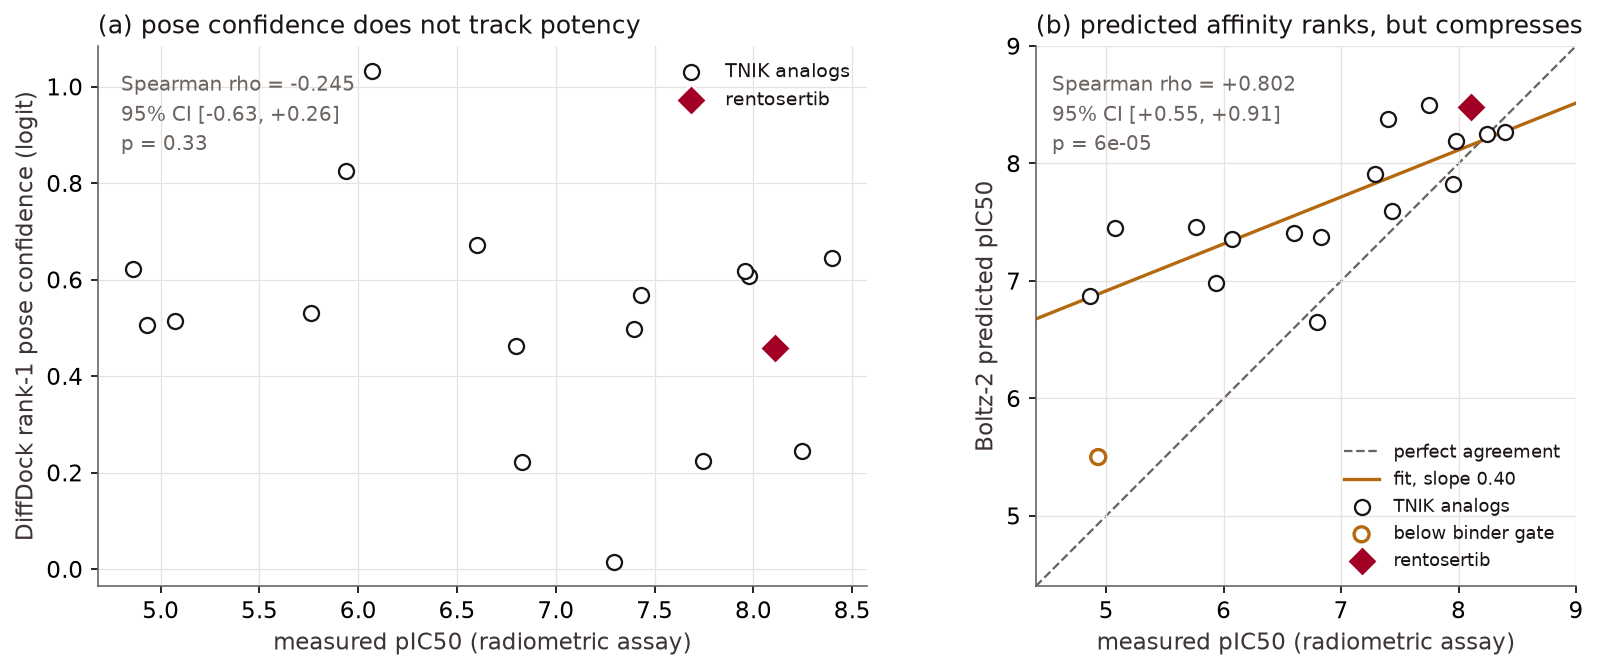

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
gate_pass = joined.passed_gate.to_numpy()

# ---- panel (a): pose confidence, which should show no trend
ax = axes[0]
ax.scatter(joined.measured_pAffinity[~joined.is_rentosertib],
           joined.rank1_position_confidence[~joined.is_rentosertib],
           s=52, facecolor="white", edgecolor=INK, linewidth=1.1, zorder=3, label="TNIK analogs")
ax.scatter(joined.measured_pAffinity[joined.is_rentosertib],
           joined.rank1_position_confidence[joined.is_rentosertib],
           s=115, marker="D", facecolor=CRIMSON, edgecolor="white", linewidth=1.3,
           zorder=4, label="rentosertib")
rho_dd, p_dd, lo_dd, hi_dd = spearman_with_ci(joined.rank1_position_confidence,
                                              joined.measured_pAffinity)
ax.set_xlabel("measured pIC50 (radiometric assay)")
ax.set_ylabel("DiffDock rank-1 pose confidence (logit)")
ax.set_title("(a) pose confidence does not track potency", loc="left", color=INK)
ax.annotate(f"Spearman rho = {rho_dd:+.3f}\n95% CI [{lo_dd:+.2f}, {hi_dd:+.2f}]\np = {p_dd:.2f}",
            xy=(0.03, 0.955), xycoords="axes fraction", va="top", fontsize=9.5,
            color=MUTED, linespacing=1.5)
ax.legend(frameon=False, fontsize=9, loc="upper right")

# ---- panel (b): predicted affinity, with the identity line for scale
ax = axes[1]
lims = (4.4, 9.0)
ax.plot(lims, lims, ls="--", lw=1.1, color=MUTED, zorder=1, label="perfect agreement")
fit = stats.linregress(joined.measured_pAffinity[gate_pass], joined.boltz2_pIC50[gate_pass])
xs = np.linspace(*lims, 50)
ax.plot(xs, fit.intercept + fit.slope * xs, lw=1.6, color=AMBER, zorder=2,
        label=f"fit, slope {fit.slope:.2f}")
plain = gate_pass & ~joined.is_rentosertib.to_numpy()
ax.scatter(joined.measured_pAffinity[plain], joined.boltz2_pIC50[plain],
           s=52, facecolor="white", edgecolor=INK, linewidth=1.1, zorder=3, label="TNIK analogs")
ax.scatter(joined.measured_pAffinity[~gate_pass], joined.boltz2_pIC50[~gate_pass],
           s=52, facecolor="none", edgecolor=AMBER, linewidth=1.6, zorder=3,
           label="below binder gate")
ax.scatter(joined.measured_pAffinity[joined.is_rentosertib],
           joined.boltz2_pIC50[joined.is_rentosertib],
           s=115, marker="D", facecolor=CRIMSON, edgecolor="white", linewidth=1.3,
           zorder=4, label="rentosertib")
rho_b2, p_b2, lo_b2, hi_b2 = spearman_with_ci(joined.boltz2_pIC50, joined.measured_pAffinity)
ax.set_xlim(*lims); ax.set_ylim(*lims); ax.set_aspect("equal")
ax.set_xlabel("measured pIC50 (radiometric assay)")
ax.set_ylabel("Boltz-2 predicted pIC50")
ax.set_title("(b) predicted affinity ranks, but compresses", loc="left", color=INK)
ax.annotate(f"Spearman rho = {rho_b2:+.3f}\n95% CI [{lo_b2:+.2f}, {hi_b2:+.2f}]\np = {p_b2:.0e}",
            xy=(0.03, 0.955), xycoords="axes fraction", va="top", fontsize=9.5,
            color=MUTED, linespacing=1.5)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")

fig.tight_layout()
fig.savefig("figures/ch13/nb1_confidence_vs_affinity.png", bbox_inches="tight")
plt.show()

<div style="font-size:12.5px;color:#6B6461;margin:6px 0 14px;">Figure 1. DiffDock pose confidence and Boltz-2 predicted affinity, each against measured potency for the same 18 TNIK inhibitors. Panel (a) plots rank-1 pose confidence (an unbounded DiffDock logit) against measured pIC50: the points show no trend, Spearman rho = -0.245 with a 95% confidence interval from -0.63 to +0.26 that comfortably spans zero, and the most confidently docked compound of the 18 is a 856 nM binder. Panel (b) plots Boltz-2 predicted pIC50 against the same measured values, with the dashed grey line marking perfect agreement: here the ranking holds at rho = +0.80, but the fitted slope of 0.40 is far below the ideal 1.0, so the predictions span a much narrower range than the measurements. Rentosertib, the clinical candidate, is highlighted in crimson in both panels; the open marker in panel (b) is the one ligand that fell below the binder-probability gate, plotted for completeness and excluded from the fit. The contrast between the panels is the point: geometric confidence and predicted affinity are different quantities, and only one of them ranks a series by potency.</div>

Read the right panel carefully. The points climb, which is the correlation we measured, but
they climb along a line much shallower than the diagonal. The most potent compound in the set is measured
at pIC50 8.40 and predicted at 8.27, close enough; the weakest is measured at 4.86 and predicted near 6.9,
two full log units too potent. The predictions occupy a narrower band than the measurements do.

In [26]:
passing = joined.loc[joined.passed_gate]
fit = stats.linregress(passing.measured_pAffinity, passing.boltz2_pIC50)

print(f"predicted-on-measured regression, {len(passing)} gate-passing TNIK ligands")
print(f"  slope        {fit.slope:.2f}   (ideal 1.0)")
print(f"  standard err {fit.stderr:.2f}")
print()
print(f"  implied compression 1/slope = {1 / fit.slope:.1f}x")
print()
print(f"measured  range {passing.measured_pAffinity.max() - passing.measured_pAffinity.min():.2f} log units")
print(f"predicted range {passing.boltz2_pIC50.max() - passing.boltz2_pIC50.min():.2f} log units")

predicted-on-measured regression, 17 gate-passing TNIK ligands
  slope        0.40   (ideal 1.0)
  standard err 0.09

  implied compression 1/slope = 2.5x

measured  range 3.54 log units
predicted range 1.85 log units


That flattening has a name and a number. Fitting predicted against measured for the
gate-passing compounds gives a slope well below one, which is range compression: the model pulls extreme
values toward the middle of its training distribution. It is the same regression-to-the-mean behaviour that
turns up throughout this book, and it has a practical consequence. Range compression preserves ranking,
which is why rho stays high, but it destroys the absolute scale, so a predicted pIC50 of 7.4 does not mean
the compound will measure 7.4.

Now the finding that should change how you use this endpoint. Alongside TNIK we ran a second
target, and comparing the two reveals something a single-target study cannot see.

In [27]:
def bias_report(frame: pd.DataFrame, label: str) -> dict:
    """Mean signed error, MAE and fitted slope for one target's gate-passing ligands."""
    d = frame.loc[frame.passed_gate].assign(pred=lambda x: 6.0 - x.affinity_pred_value)
    err = d.pred - d.measured_pAffinity
    fitted = stats.linregress(d.measured_pAffinity, d.pred)
    return {"target": label, "n": len(d), "mean signed error": round(err.mean(), 2),
            "MAE": round(err.abs().mean(), 2), "slope": round(fitted.slope, 2),
            "measured range": round(d.measured_pAffinity.max() - d.measured_pAffinity.min(), 2)}


# TYK2 potencies come from a free-energy-perturbation benchmark; drop the censored
# measurements (recorded as greater-than values), which cannot enter a rank correlation.
tyk2_uncensored = tyk2.loc[~tyk2.censored.astype(bool)]

bias = pd.DataFrame([bias_report(tnik, "TNIK"), bias_report(tyk2_uncensored, "TYK2")])
print(bias.to_string(index=False))
print()
print("Mean signed error is positive on TNIK and negative on TYK2: the model is too")
print("optimistic on one target and too pessimistic on the other, by comparable amounts.")

target  n  mean signed error  MAE  slope  measured range
  TNIK 17               0.73 0.78   0.40            3.54
  TYK2 12              -1.10 1.10   0.23            2.00

Mean signed error is positive on TNIK and negative on TYK2: the model is too
optimistic on one target and too pessimistic on the other, by comparable amounts.


The two targets are biased in opposite directions. On TNIK the model is 0.73 log units too
optimistic on average; on TYK2 it is 1.10 log units too pessimistic. Neither is a large error by the
standards of affinity prediction. But they have opposite signs, and that is fatal for the one operation a
screening pipeline most wants to perform: comparing predictions across targets. A single per-target offset
would be easy to calibrate away with a handful of measured compounds. Offsets that differ in sign between
targets mean the correction has to be learned per target, from data you do not have when you are screening
a new one.

Pool the two gated sets and the ranking signal disappears.

In [28]:
pooled = pd.concat([
    tnik.loc[tnik.passed_gate].assign(target="TNIK"),
    tyk2_uncensored.loc[tyk2_uncensored.passed_gate].assign(target="TYK2"),
]).assign(pred=lambda d: 6.0 - d.affinity_pred_value)

def fmt_p(p: float) -> str:
    """Format a p-value at Table 13.1's precision: 4 decimals below 0.001, else 3."""
    return f"{p:.4f}" if p < 0.001 else f"{p:.3f}"


print("within-target versus pooled Spearman rho")
for name, grp in pooled.groupby("target"):
    r = stats.spearmanr(grp.pred, grp.measured_pAffinity)
    print(f"  {name} alone   n = {len(grp):2d}   rho = {r.statistic:+.2f}   "
          f"p = {fmt_p(r.pvalue)}")

r_pool = stats.spearmanr(pooled.pred, pooled.measured_pAffinity)
print(f"  POOLED       n = {len(pooled):2d}   rho = {r_pool.statistic:+.2f}   "
      f"p = {fmt_p(r_pool.pvalue)}")
print()

# For reference, the same targets before the gate is applied. Gating removes the
# compounds the model is least sure about, which costs a little rank correlation.
for name, grp in [("TNIK", tnik), ("TYK2", tyk2_uncensored)]:
    r = stats.spearmanr(6.0 - grp.affinity_pred_value, grp.measured_pAffinity)
    print(f"  {name}, gate ignored   n = {len(grp):2d}   rho = {r.statistic:+.2f}   "
          f"p = {fmt_p(r.pvalue)}")
print()
print("The pooled measured range is wider than either target alone, so this is not a")
print("loss of dynamic range. It is the two per-target offsets pulling in opposite")
print("directions and cancelling the signal.")

within-target versus pooled Spearman rho
  TNIK alone   n = 17   rho = +0.77   p = 0.0003
  TYK2 alone   n = 12   rho = +0.42   p = 0.175
  POOLED       n = 29   rho = +0.17   p = 0.375

  TNIK, gate ignored   n = 18   rho = +0.80   p = 0.0001
  TYK2, gate ignored   n = 15   rho = +0.69   p = 0.005

The pooled measured range is wider than either target alone, so this is not a
loss of dynamic range. It is the two per-target offsets pulling in opposite
directions and cancelling the signal.


<div style="margin:0 0 16px;padding:12px 18px;border-left:2px solid #A20025;background:#FDF3F5;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#A20025;">Key result</strong><br>
<span style="color:#3d3436;font-size:14.5px;">Boltz-2 ranks compounds well <em>within</em> a target and not at all
<em>across</em> targets. On the gate-passing compounds, TNIK alone gives rho = +0.77 (n = 17, p = 0.0003)
and TYK2 alone rho = +0.42 (n = 12, p = 0.17, underpowered), but pooling all 29 collapses this to
rho = +0.17 (p = 0.375). The reason is visible in the bias: the model runs +0.73 log units too potent on
TNIK and -1.10 log units too weak on TYK2. Use these predictions to rank a congeneric series against
itself. Do not use them to decide which of two targets has the better chemical series.</span>
</div>

One more operating characteristic worth measuring, because it tells you where the error
budget actually goes. Twelve ligands were called three times each with identical payloads, which gives us a
direct read on how much of the error is stochastic.

In [29]:
reps = cached_calls.loc[cached_calls.n_replicates > 1]

# Pool the within-ligand standard deviations into one noise floor.
noise_sd = float(np.sqrt((reps.apv_sd ** 2).mean()))

print(f"{len(reps)} ligands called {int(reps.n_replicates.iloc[0])} times each with identical payloads")
print(f"  pooled within-ligand SD    {noise_sd:.3f} log units")
print(f"  95% interval, single call  +/- {1.96 * noise_sd:.2f} log units")
print(f"  largest single-ligand SD   {reps.apv_sd.max():.3f}")
print()
for row in bias.itertuples():                       # MAE from the table computed above
    print(f"  MAE vs experiment, {row.target}: {row.MAE:.2f} log "
          f"= {row.MAE / noise_sd:.0f}x the noise floor")
print()
print("Accuracy here is limited by systematic bias, not by stochasticity, so averaging")
print("repeated calls buys almost nothing.")

12 ligands called 3 times each with identical payloads
  pooled within-ligand SD    0.054 log units
  95% interval, single call  +/- 0.11 log units
  largest single-ligand SD   0.079

  MAE vs experiment, TNIK: 0.78 log = 14x the noise floor
  MAE vs experiment, TYK2: 1.10 log = 20x the noise floor

Accuracy here is limited by systematic bias, not by stochasticity, so averaging
repeated calls buys almost nothing.


The single-call noise is roughly 0.05 log units, so a single prediction carries about a
0.11 log unit interval. Compare that with the mean absolute error against experiment, 0.78 log units on
TNIK and 1.10 on TYK2: the error is 14 to 20 times larger than the noise. That ratio is the useful number.
It says the accuracy limit here is systematic bias, not sampling variance, so averaging repeated calls will
buy you almost nothing. If you want a better number you need a better model or a local calibration, not
more replicates.

Finally, the cost. If you are sizing a screen, the number you want is server compute, not
wall-clock, because wall-clock here is mostly someone else's queue.

In [30]:
timing = pd.read_csv(DATA / "boltz2_affinity_timing.csv")

total_calls = int(timing.n_calls.sum())
wall_total = timing.wall_total_s.sum()
srv_total = timing.srv_total_s.sum()

print(f"{total_calls} Boltz-2 calls")
print(f"  wall-clock total    {wall_total:,.1f} s ({wall_total / 60:.1f} min)")
print(f"  server compute      {srv_total:,.1f} s ({100 * srv_total / wall_total:.1f}% of wall)")
print(f"  queue overhead      {wall_total - srv_total:,.1f} s")
print()

print("wall-clock per call is widely dispersed:")
for row in timing.itertuples():
    print(f"  {row.set_name}: {row.wall_min_s:5.1f} s min, {row.wall_median_s:5.1f} s median, "
          f"{row.wall_max_s:5.1f} s max")
print("server compute per call is not:")
for row in timing.itertuples():
    print(f"  {row.set_name}: {row.srv_min_s:5.2f} s min, {row.srv_mean_s:5.2f} s mean, "
          f"{row.srv_max_s:5.2f} s max")
print()
print(f"Plan on about {srv_total / total_calls:.1f} GPU-seconds per ligand. A factor of five")
print("spread in wall-clock sitting on top of a near-constant compute time is a queue,")
print("not a model.")

58 Boltz-2 calls
  wall-clock total    1,604.9 s (26.7 min)
  server compute      325.5 s (20.3% of wall)
  queue overhead      1,279.4 s

wall-clock per call is widely dispersed:
  TNIK:   8.5 s min,  16.5 s median,  47.4 s max
  TYK2:  10.7 s min,  25.1 s median,  47.3 s max
server compute per call is not:
  TNIK:  5.53 s min,  5.63 s mean,  5.82 s max
  TYK2:  5.49 s min,  5.60 s mean,  5.83 s max

Plan on about 5.6 GPU-seconds per ligand. A factor of five
spread in wall-clock sitting on top of a near-constant compute time is a queue,
not a model.


Server compute per call is remarkably steady
at about 5.6 seconds, varying by less than a third of a second across 58 calls, while wall-clock for the
same calls ranges from 8.5 to 47.4 seconds depending on queue depth at the moment you ask. So the
defensible throughput figure for planning is roughly 5.6 GPU-seconds per ligand. So the eight minutes or so you will wait
for 18 ligands is a property of a shared free-tier endpoint rather than of the model, and it is the part of
the cost that a dedicated deployment of the same NIM would remove.

<div style="margin:0 0 16px;padding:2px 0 2px 18px;border-left:2px solid #A20025;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#A20025;">Note</strong><br>
<span style="color:#3d3436;font-size:14.5px;">This is also why the live path will not reproduce the cached numbers exactly, and why
<code>USE_CACHED = True</code> is the default. Boltz-2 affinity is stochastic: three consecutive identical
calls during preparation of this notebook returned <code>affinity_pred_value</code> of -2.703, -2.734 and
-2.781. Session-to-session drift is larger still. Every figure quoted in the prose comes from the cached
CSVs so that the notebook and the text cannot disagree; run live to see the pipeline work, then trust the
cached values for the numbers.</span>
</div>

<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:34px 0 10px;color:#1A1416;"><span style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:13px;color:#A20025;font-weight:500;">§6&#8195;</span>What DiffDock Is Actually Good At</h2>

We have been hard on DiffDock for three sections, so it is worth showing what it is actually
good at, and being equally careful about what that demonstration proves.

The question is pose recovery: given the receptor and the ligand, can the model reproduce the
crystallographic binding geometry? For rentosertib we have the answer key, PDB 8ZML. The standard measure
is root-mean-square deviation (RMSD) between predicted and crystal heavy-atom positions, with 2 Angstroms
the conventional threshold for a correct pose.

One methodological note first, because getting this wrong silently changes your conclusion.
RMSD must be computed in place, on the coordinates as they sit in the binding site, with molecular symmetry
accounted for so that chemically equivalent atoms are not penalised for swapping labels. RDKit's `CalcRMS`
does this. Its neighbour `GetBestRMS` superposes the two molecules first and then measures, which answers a
different question: how similar are these two conformers, ignoring where they are. On a badly placed pose
the two disagree wildly.

In [31]:
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolAlign

reference = Chem.MolFromMolFile(str(DATA / "8ZML_rentosertib_refpose.sdf"))
docked = Chem.MolFromMolFile(str(DATA / "rentosertib_rank1_pose.sdf"))

# CalcRMS: symmetry-corrected, measured where the atoms sit. This is the right metric.
rmsd_in_place = rdMolAlign.CalcRMS(Chem.RemoveHs(docked), Chem.RemoveHs(reference))

print(f"reference : {reference.GetNumHeavyAtoms()} heavy atoms from 8ZML")
print(f"docked    : {docked.GetNumHeavyAtoms()} heavy atoms, DiffDock rank-1")
print(f"same molecule: {Chem.MolToInchiKey(Chem.RemoveHs(docked))[:14] == Chem.MolToInchiKey(Chem.RemoveHs(reference))[:14]}")
print()
print(f"rank-1 RMSD, symmetry-corrected in place: {rmsd_in_place:.3f} Angstroms")

reference : 36 heavy atoms from 8ZML
docked    : 36 heavy atoms, DiffDock rank-1
same molecule: True

rank-1 RMSD, symmetry-corrected in place: 0.923 Angstroms


In [32]:
poses = pd.read_csv(DATA / "rentosertib_rank_vs_rmsd.csv")
headline = poses.query("run == 'headline'").sort_values("rank")

# The two metrics agree on a good pose and diverge completely on a bad one.
comparison = headline.loc[headline["rank"].isin([1, 10, 19]),
                          ["rank", "position_confidence",
                           "rmsd_symmcorr_inplace_A", "rmsd_superposed_A"]]
print(comparison.to_string(index=False))
print()
worst = headline.loc[headline["rank"] == 19].iloc[0]
print(f"At rank 19 the in-place RMSD is {worst.rmsd_symmcorr_inplace_A:.3f} Angstroms")
print(f"but the superposing metric reports only {worst.rmsd_superposed_A:.3f}.")
print("The first says 'wrong place'. The second says 'similar shape'. Only the first")
print("answers the docking question.")

 rank  position_confidence  rmsd_symmcorr_inplace_A  rmsd_superposed_A
    1               0.4235                    0.923              0.806
   10              -0.0507                    1.217              1.056
   19              -3.0925                   18.397              3.272

At rank 19 the in-place RMSD is 18.397 Angstroms
but the superposing metric reports only 3.272.
The first says 'wrong place'. The second says 'similar shape'. Only the first
answers the docking question.


A pose that is 18.4 Angstroms from the reference where it sits reports 3.3 Angstroms after
superposition. If you use the superposing metric you will conclude that a pose in the wrong pocket entirely
is a near miss. Use the in-place, symmetry-corrected metric.

With the right metric, the result is genuinely good.

In [33]:
print(f"rank-1 RMSD          {headline.rmsd_symmcorr_inplace_A.iloc[0]:.3f} Angstroms")
print(f"best of the 20 poses {headline.rmsd_symmcorr_inplace_A.min():.3f} Angstroms "
      f"(at rank {int(headline.loc[headline.rmsd_symmcorr_inplace_A.idxmin(), 'rank'])})")
print(f"poses under 2 Angstroms: {int(headline.under_2A.sum())} of {len(headline)}")
print()

rank1 = poses.query("rank == 1")
print(f"rank-1 RMSD across {len(rank1)} independent runs")
print(f"  values {', '.join(f'{v:.3f}' for v in rank1.rmsd_symmcorr_inplace_A)}")
print(f"  mean {rank1.rmsd_symmcorr_inplace_A.mean():.3f}, "
      f"sd {rank1.rmsd_symmcorr_inplace_A.std(ddof=1):.3f} Angstroms")
print()

print(f"all {len(docking)} TNIK ligands, rank-1 pose")
print(f"  landed in the ATP site        {int(docking.in_atp_site.sum())} of {len(docking)}")
print(f"  centroid distance to reference {docking.centroid_dist_to_ref_A.min():.2f} to "
      f"{docking.centroid_dist_to_ref_A.max():.2f} Angstroms")
print(f"  contacting Met105 gatekeeper  {int(docking.contacts_gatekeeper_M105.sum())} of {len(docking)}")
print(f"  contacting Cys108 hinge       {int(docking.contacts_hinge_C108.sum())} of {len(docking)}")

rank-1 RMSD          0.923 Angstroms
best of the 20 poses 0.923 Angstroms (at rank 1)
poses under 2 Angstroms: 14 of 20

rank-1 RMSD across 4 independent runs
  values 0.923, 0.809, 0.854, 0.703
  mean 0.822, sd 0.092 Angstroms

all 18 TNIK ligands, rank-1 pose
  landed in the ATP site        18 of 18
  centroid distance to reference 0.11 to 2.44 Angstroms
  contacting Met105 gatekeeper  18 of 18
  contacting Cys108 hinge       18 of 18


<div style="margin:0 0 16px;padding:12px 18px;border-left:2px solid #A20025;background:#FDF3F5;">
<strong style="font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:10.5px;letter-spacing:.16em;text-transform:uppercase;color:#A20025;">Key result</strong><br>
<span style="color:#3d3436;font-size:14.5px;">DiffDock places rentosertib in the TNIK ATP site at 0.923 Angstroms
heavy-atom RMSD from the 8ZML crystal pose, and the rank-1 pose is also the best of the 20 returned, so the
confidence ordering picked the right one. Four independent runs gave 0.923, 0.809, 0.854 and 0.703
Angstroms, all sub-Angstrom. Across all 18 ligands every rank-1 pose landed in the ATP site, contacting the
Met105 gatekeeper and the Cys108 hinge, with zero off-site failures.</span>
</div>

Now the caveat, and it is not a small one. **Nothing in this notebook is a held-out test.**
8ZML is a rentosertib co-crystal deposited in the PDB. The DiffDock NIM's weights were trained by NVIDIA on
PLINDER and SAIR, both curated from the PDB. Boltz-2 was trained on PDB structures deposited before
2021-09-30, and both ligand series predate that cutoff. So what we measured is pose recovery and units
calibration on data the models may well have seen, not blind prospective prediction. Do not read the 0.92
Angstroms as an expected accuracy on your next novel target.

There is a redeeming logic to this, and it runs in a useful direction. Memorisation would tend to *hide*
negative results, not create them. If these models had simply memorised the answers, the opposite-signed
per-target bias, the range compression, and the cross-target collapse would not be there. Those findings
survive the training-data problem, which makes them the more trustworthy half of this exercise. The
positive results are the ones to discount.

<h3 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:600;font-size:17px;color:#1A1416;margin:24px 0 8px;">Two corrections for the record</h3>

A last correction that matters if you plan to cite the chapter's accuracy figure. Chapter
13 quotes roughly 38% of top-ranked poses within 2 Angstroms on the PDBBind blind-docking benchmark, from
the original DiffDock paper. That figure does not describe this endpoint. The hosted NIM serves weights
NVIDIA retrained on 486,000 complexes (450,000 from PLINDER plus 36,000 from SAIR), and NVIDIA evaluates
them on PoseBusters rather than PDBBind. The architecture is unchanged, so the citation to Corso et al.
remains correct for the model design; the accuracy number belongs to different weights measured on a
different benchmark. Two things changed at once, which is exactly when a transferred benchmark figure stops
meaning anything.

Also worth knowing before you build anything on these endpoints: NVIDIA's API trial terms
limit use to internal testing and evaluation, not production, absent a paid subscription, and under the
privacy section NVIDIA collects both your inputs and the generated outputs to improve its own products and
services, including AI models. If your inputs are proprietary chemistry, that second clause is the one to
read carefully. There is no blanket prohibition on training other models from the outputs; the restriction
is competitive rather than general.

<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:34px 0 12px;">
<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:0 0 10px;color:#1A1416;">Summary</h2>

We set out to make one unglamorous claim from Chapter 13 concrete, that each BioNeMo NIM
exposes a REST API for inference, and we found that the interesting work begins immediately after the
response arrives. Two hosted endpoints, 18 TNIK inhibitors from a single assay, one co-crystal structure,
and a few dozen HTTP calls were enough to separate what these models tell you from what their field names
suggest they tell you.

The units trap is the finding to carry away. The Boltz-2 NIM returns a field named `affinity_pic50`, and
that field is wrong by an exact factor of 1.364, which is $RT\ln(10)$ in kcal/mol at room temperature: a
free-energy conversion applied to a quantity already in log units. It places rentosertib at sub-picomolar
potency against a measured 7.8 nM. The correct conversion is one subtraction, `pIC50 = 6 -
affinity_pred_value`, and the ratio between the two is constant to ten decimal places across every call we
made, so this is a deterministic error hiding behind a plausible name rather than noise you might average
away. The same discipline applies to the binder-probability gate: ask whether the ligand binds before
asking how tightly, because the endpoint will hand you a crisp six-decimal affinity for a compound it does
not believe binds at all, and nothing in the response marks that number as untrustworthy.

On the substantive question, the chapter's division of labour held up under measurement. Boltz-2 predicted
affinity ranked the 18-compound series against measured potency at Spearman rho = +0.80, while DiffDock
rank-1 pose confidence managed rho = -0.245 with a confidence interval spanning zero. Pose confidence is a
geometry score and carries no potency information, which is what the chapter says and is now something you
have measured rather than accepted. DiffDock was meanwhile excellent at its actual job, placing rentosertib
at 0.923 Angstroms from the crystal pose with the rank-1 pose also being the best of 20.

The three limits are as important as the results. Predicted affinities are range-compressed, with a fitted
slope of 0.40 rather than 1.0, so ranking survives but the absolute scale does not. The per-target bias
runs in opposite directions, +0.73 log units too potent on TNIK and -1.10 too weak on TYK2, which is why
pooling both targets collapses the correlation to rho = +0.17 and why these numbers must not be used to
compare across targets. And the single-call noise floor of 0.054 log units is 14 to 20 times smaller than
the error against experiment, which tells you the accuracy ceiling here is systematic bias rather than
sampling variance, so more replicates will not help.

Finally, and this is the honest framing the results demand: nothing here was a held-out test. The
co-crystal is in the PDB, the DiffDock weights are PDB-derived, and both ligand series predate Boltz-2's
training cutoff. What we measured is pose recovery and units calibration, not prospective prediction. That
cuts in a specific direction worth stating plainly. Memorisation would conceal negative results rather than
manufacture them, so the opposite-signed bias, the range compression, and the cross-target collapse are the
findings that survive the caveat, and the sub-Angstrom pose is the one to discount.

<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:34px 0 12px;">
<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:0 0 10px;color:#1A1416;">Interactive Exploration</h2>

<details style="margin:0 0 14px;border-top:1px solid #E7E2DF;border-bottom:1px solid #E7E2DF;">
<summary style="cursor:pointer;padding:11px 0;font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:12px;letter-spacing:.05em;text-transform:uppercase;color:#A20025;">Try it yourself &middot; Where should the gate sit?</summary>
<div style="padding:4px 0 14px;font-size:14.5px;color:#3d3436;">
<p>The notebook gates at the conventional `affinity_probability_binary >= 0.5`. That
threshold is a convention, not a measurement. Using the cached TYK2 and TNIK results together, sweep the
threshold from 0.3 to 0.7 and plot how many compounds survive and what the within-target Spearman rho does
as the gate tightens. Is there a threshold that improves the correlation, and if so, is the improvement
real or is it just removing the compounds that were hardest to predict?</p>
</div>
</details>

<details style="margin:0 0 14px;border-top:1px solid #E7E2DF;border-bottom:1px solid #E7E2DF;">
<summary style="cursor:pointer;padding:11px 0;font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:12px;letter-spacing:.05em;text-transform:uppercase;color:#A20025;">Try it yourself &middot; Calibrating the per-target offset</summary>
<div style="padding:4px 0 14px;font-size:14.5px;color:#3d3436;">
<p>Section 5 shows a per-target offset with opposite signs. Suppose you had measured
potencies for three compounds on a new target. Write a function that fits a single additive offset from
those three and applies it to the rest, then test it by leave-one-out on the TNIK set: hold out one
compound, calibrate on a random three of the remaining 17, and see how much the absolute error falls.
How many anchor compounds do you need before the correction is worth making?</p>
</div>
</details>

<details style="margin:0 0 14px;border-top:1px solid #E7E2DF;border-bottom:1px solid #E7E2DF;">
<summary style="cursor:pointer;padding:11px 0;font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:12px;letter-spacing:.05em;text-transform:uppercase;color:#A20025;">Try it yourself &middot; Is rank 1 the best pose?</summary>
<div style="padding:4px 0 14px;font-size:14.5px;color:#3d3436;">
<p>The rank-1 pose was also the best of 20 for rentosertib. Is that typical? Using
`rentosertib_rank_vs_rmsd.csv`, which holds all 20 poses from four independent runs, compute how often the
best-RMSD pose is the top-ranked one, and how much RMSD you would give up by always taking rank 1 rather
than an oracle that picks the best. Then ask the harder question: with no crystal structure available, is
there anything in the confidence values that would let you tell a good run from a bad one?</p>
</div>
</details>

<details style="margin:0 0 14px;border-top:1px solid #E7E2DF;border-bottom:1px solid #E7E2DF;">
<summary style="cursor:pointer;padding:11px 0;font-family:ui-monospace,'SF Mono','JetBrains Mono',Menlo,monospace;font-size:12px;letter-spacing:.05em;text-transform:uppercase;color:#A20025;">Try it yourself &middot; One receptor is a choice</summary>
<div style="padding:4px 0 14px;font-size:14.5px;color:#3d3436;">
<p>This notebook uses one receptor conformation, chain A of 8ZML, for all 18 ligands.
Kinases are flexible and the ATP site changes shape between co-crystals. Pick a second TNIK structure from
the PDB, prepare it the same way, dock the same series into it, and compare the two sets of confidences and
poses. How much of the pose-confidence variation you attributed to the ligands was actually a property of
the receptor you chose?</p>
</div>
</details>

<hr style="border:0;border-top:1px solid #A20025;opacity:.55;margin:34px 0 12px;">
<h2 style="font-family:Georgia,'Iowan Old Style','Palatino Linotype',serif;font-weight:500;font-size:23px;margin:0 0 10px;color:#1A1416;">References</h2>

<ol style="font-size:13.5px;color:#6B6461;padding-left:20px;">
<li style="margin:7px 0;">Aladinskiy, V. et al. (2024). <em>Discovery of a Potent and Selective TNIK Inhibitor for the Treatment of Idiopathic Pulmonary Fibrosis.</em> J. Med. Chem. 67. doi:10.1021/acs.jmedchem.4c01580. Source of the 18-compound TNIK series and its radiometric IC50 values.</li>
<li style="margin:7px 0;">Ren, F. et al. (2025). <em>A small-molecule TNIK inhibitor targets fibrosis in preclinical and clinical models.</em> Nature Biotechnology 43, 63-75. doi:10.1038/s41587-024-02143-0. Rentosertib discovery; reports IC50 31 nM and SPR Kd 4.32 nM against a 430-kinase panel.</li>
<li style="margin:7px 0;">Wohlwend, J. et al. (2024). <em>Boltz-1: Democratizing Biomolecular Interaction Modeling</em>, and Passaro, S. et al. (2025). <em>Boltz-2: Towards Accurate and Efficient Binding Affinity Prediction.</em> MIT. The model served by the Boltz-2 NIM.</li>
<li style="margin:7px 0;">Corso, G., Stark, H., Jing, B., Barzilay, R. and Jaakkola, T. (2023). <em>DiffDock: Diffusion Steps, Twists, and Turns for Molecular Docking.</em> ICLR 2023. The architecture served by the DiffDock NIM; note that the hosted weights are NVIDIA retrained.</li>
<li style="margin:7px 0;">Durrant, J. et al. (2024). <em>PLINDER: The protein-ligand interactions dataset and evaluation resource.</em> Plus SAIR (Structurally Augmented IC50 Repository). The training data for the served DiffDock weights, 486,000 complexes in total.</li>
<li style="margin:7px 0;">Schindler, C. et al. (2020). <em>Large-Scale Assessment of Binding Free Energy Calculations in Active Drug Discovery Projects.</em> J. Chem. Inf. Model. 60. The TYK2 congeneric series used as the second target.</li>
<li style="margin:7px 0;">PDB 8ZML. <em>Crystal structure of TNIK in complex with rentosertib.</em> RCSB Protein Data Bank. doi:10.2210/pdb8ZML/pdb. The pose-recovery reference.</li>
<li style="margin:7px 0;">NVIDIA (2026). <em>Boltz-2 and DiffDock NIM model cards.</em> build.nvidia.com/mit/boltz2 and build.nvidia.com/mit/diffdock, accessed 2026-07-29. Source of the log-micromolar affinity scale, the retrained-weights statement, and the training-data provenance.</li>
<li style="margin:7px 0;">Landrum, G. et al. <em>RDKit: Open-source cheminformatics.</em> rdkit.org. <code>AllChem.CalcRMS</code> supplies the symmetry-corrected in-place RMSD used in section 6.</li>
</ol>